In [3]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

df = pd.read_csv(
    "../data/processed/cleaned_customer_data.csv"
)

print(df.shape)

(7043, 21)


In [4]:
df = df.drop(columns=["customerID"])

X = df.drop(columns=["Churn"])

y = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

In [5]:
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

In [6]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (5634, 19)
Testing: (1409, 19)


In [9]:
rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            max_depth=None,
            min_samples_split=2,
            min_samples_leaf=1,
            random_state=42,
            n_jobs=-1
        ))
    ]
)
rf_model.fit(X_train, y_train)

print("Random Forest training completed!")

rf_pred = rf_model.predict(X_test)

rf_prob = rf_model.predict_proba(X_test)[:, 1]
print("Accuracy:",
      accuracy_score(y_test, rf_pred))

print("Precision:",
      precision_score(y_test, rf_pred))

print("Recall:",
      recall_score(y_test, rf_pred))

print("F1 Score:",
      f1_score(y_test, rf_pred))

print("ROC-AUC:",
      roc_auc_score(y_test, rf_prob))

print("\nClassification Report:")
print(classification_report(y_test, rf_pred))

Random Forest training completed!
Accuracy: 0.7835344215755855
Precision: 0.6185567010309279
Recall: 0.48128342245989303
F1 Score: 0.5413533834586466
ROC-AUC: 0.820602443876101

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.89      0.86      1035
           1       0.62      0.48      0.54       374

    accuracy                           0.78      1409
   macro avg       0.72      0.69      0.70      1409
weighted avg       0.77      0.78      0.77      1409



In [10]:
# Get transformed feature names
feature_names = (
    rf_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

# Get feature importance
importances = (
    rf_model.named_steps["classifier"]
    .feature_importances_
)

# Create DataFrame
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(importance_df.head(15))


                                Feature  Importance
3                     num__TotalCharges    0.157102
1                           num__tenure    0.142508
2                   num__MonthlyCharges    0.137807
36         cat__Contract_Month-to-month    0.053097
18               cat__OnlineSecurity_No    0.032972
43  cat__PaymentMethod_Electronic check    0.030101
27                  cat__TechSupport_No    0.028003
16     cat__InternetService_Fiber optic    0.026064
0                    num__SeniorCitizen    0.019436
21                 cat__OnlineBackup_No    0.018395
5                      cat__gender_Male    0.018052
4                    cat__gender_Female    0.017777
38               cat__Contract_Two year    0.016358
40            cat__PaperlessBilling_Yes    0.016206
24             cat__DeviceProtection_No    0.015680


In [11]:
rf_balanced = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            max_depth=15,
            min_samples_split=5,
            min_samples_leaf=2,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ]
)
rf_balanced.fit(X_train, y_train)

rf_balanced_pred = rf_balanced.predict(X_test)

rf_balanced_prob = (
    rf_balanced.predict_proba(X_test)[:, 1]
)
print("Accuracy:",
      accuracy_score(y_test, rf_balanced_pred))

print("Precision:",
      precision_score(y_test, rf_balanced_pred))

print("Recall:",
      recall_score(y_test, rf_balanced_pred))

print("F1 Score:",
      f1_score(y_test, rf_balanced_pred))

print("ROC-AUC:",
      roc_auc_score(y_test, rf_balanced_prob))

print("\nClassification Report:")
print(classification_report(y_test, rf_balanced_pred))

Accuracy: 0.752306600425834
Precision: 0.52465483234714
Recall: 0.7112299465240641
F1 Score: 0.6038592508513053
ROC-AUC: 0.8342581828515332

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.77      0.82      1035
           1       0.52      0.71      0.60       374

    accuracy                           0.75      1409
   macro avg       0.70      0.74      0.71      1409
weighted avg       0.79      0.75      0.76      1409



In [12]:
balanced_importance = (
    rf_balanced.named_steps["classifier"].feature_importances_
)

feature_names = (
    rf_balanced.named_steps["preprocessor"]
    .get_feature_names_out()
)

balanced_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": balanced_importance
})

balanced_importance_df = (
    balanced_importance_df
    .sort_values("Importance", ascending=False)
)

print(balanced_importance_df.head(15))


                                Feature  Importance
1                           num__tenure    0.125995
3                     num__TotalCharges    0.119556
36         cat__Contract_Month-to-month    0.102083
2                   num__MonthlyCharges    0.093140
38               cat__Contract_Two year    0.051682
18               cat__OnlineSecurity_No    0.047794
27                  cat__TechSupport_No    0.041137
16     cat__InternetService_Fiber optic    0.037551
43  cat__PaymentMethod_Electronic check    0.033211
21                 cat__OnlineBackup_No    0.017585
37               cat__Contract_One year    0.016329
15             cat__InternetService_DSL    0.014408
20              cat__OnlineSecurity_Yes    0.014132
40            cat__PaperlessBilling_Yes    0.013327
39             cat__PaperlessBilling_No    0.013075


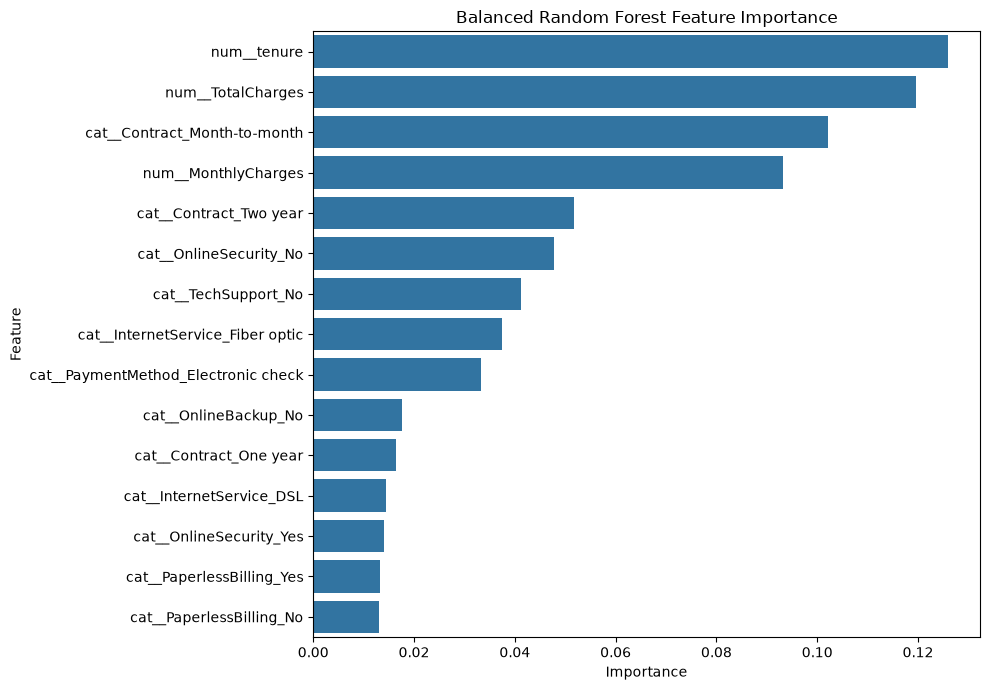

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(10, 7))

sns.barplot(
    data=balanced_importance_df.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Balanced Random Forest Feature Importance")
plt.tight_layout()
plt.show()

In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)
# Extract trained logistic regression model
lr_classifier = logistic_model.named_steps["classifier"]

# Get transformed feature names
lr_feature_names = (
    logistic_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

# Extract coefficients
lr_coefficients = lr_classifier.coef_[0]

# Create DataFrame
coefficient_df = pd.DataFrame({
    "Feature": lr_feature_names,
    "Coefficient": lr_coefficients
})

# Sort by coefficient
coefficient_df["Absolute_Value"] = (
    coefficient_df["Coefficient"].abs()
)

coefficient_df = coefficient_df.sort_values(
    "Absolute_Value",
    ascending=False
)

print(coefficient_df.head(20))

                                       Feature  Coefficient  Absolute_Value
1                                  num__tenure    -1.257539        1.257539
38                      cat__Contract_Two year    -0.776594        0.776594
15                    cat__InternetService_DSL    -0.648646        0.648646
16            cat__InternetService_Fiber optic     0.634195        0.634195
2                          num__MonthlyCharges    -0.591863        0.591863
36                cat__Contract_Month-to-month     0.582883        0.582883
3                            num__TotalCharges     0.536253        0.536253
39                    cat__PaperlessBilling_No    -0.343227        0.343227
25   cat__DeviceProtection_No internet service    -0.300104        0.300104
17                     cat__InternetService_No    -0.300104        0.300104
19     cat__OnlineSecurity_No internet service    -0.300104        0.300104
28        cat__TechSupport_No internet service    -0.300104        0.300104
31        ca

In [16]:
coefficient_df["Odds_Ratio"] = np.exp(
    coefficient_df["Coefficient"]
)

print(
    coefficient_df[
        ["Feature", "Coefficient", "Odds_Ratio"]
    ].head(20).to_string(index=False)
)

                                   Feature  Coefficient  Odds_Ratio
                               num__tenure    -1.257539    0.284353
                    cat__Contract_Two year    -0.776594    0.459970
                  cat__InternetService_DSL    -0.648646    0.522753
          cat__InternetService_Fiber optic     0.634195    1.885504
                       num__MonthlyCharges    -0.591863    0.553295
              cat__Contract_Month-to-month     0.582883    1.791195
                         num__TotalCharges     0.536253    1.709590
                  cat__PaperlessBilling_No    -0.343227    0.709477
 cat__DeviceProtection_No internet service    -0.300104    0.740741
                   cat__InternetService_No    -0.300104    0.740741
   cat__OnlineSecurity_No internet service    -0.300104    0.740741
      cat__TechSupport_No internet service    -0.300104    0.740741
      cat__StreamingTV_No internet service    -0.300104    0.740741
     cat__OnlineBackup_No internet service    -0

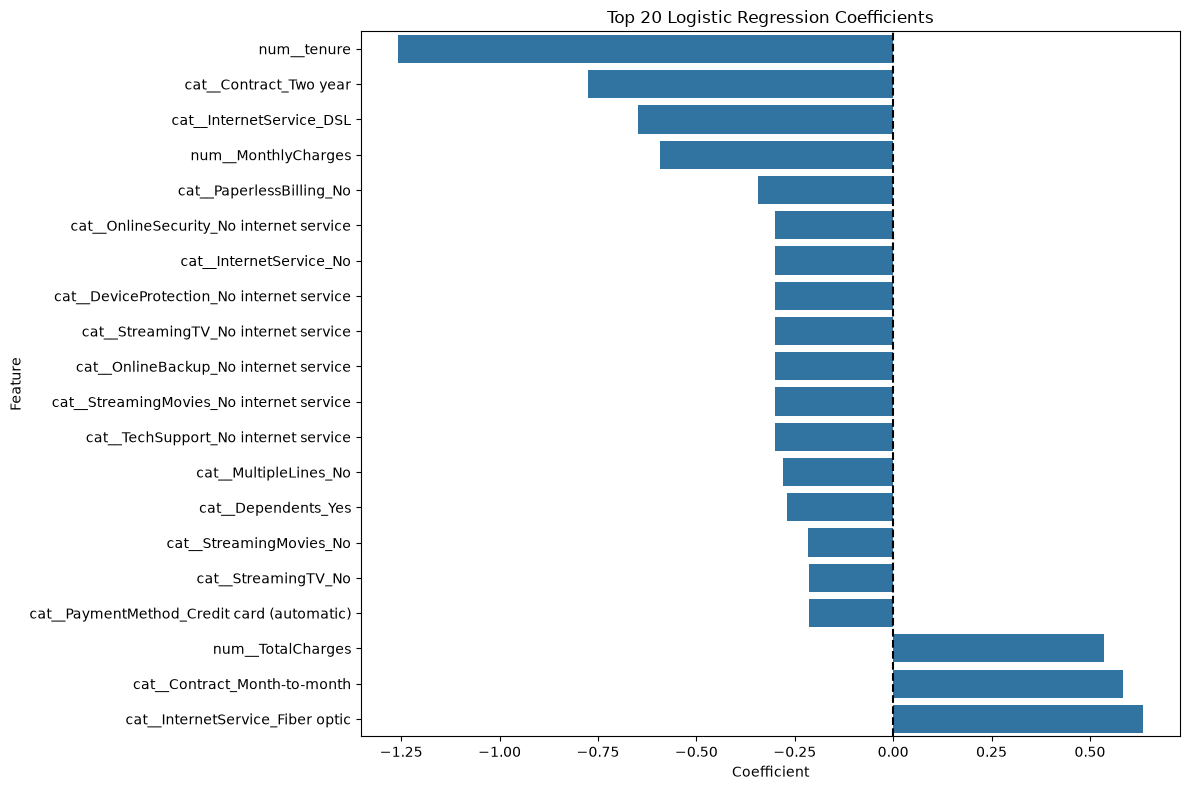

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

top_features = coefficient_df.head(20).sort_values(
    "Coefficient"
)

plt.figure(figsize=(12, 8))

sns.barplot(
    data=top_features,
    x="Coefficient",
    y="Feature"
)

plt.axvline(x=0, color="black", linestyle="--")

plt.title("Top 20 Logistic Regression Coefficients")
plt.xlabel("Coefficient")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [19]:
from sklearn.inspection import permutation_importance

perm_result = permutation_importance(
    rf_balanced,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring="f1",
    n_jobs=-1
)

permutation_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": perm_result["importances_mean"]
})

permutation_df = permutation_df.sort_values(
    "Importance",
    ascending=False
)

print(permutation_df.head(15))

             Feature  Importance
14          Contract    0.094528
7    InternetService    0.024427
4             tenure    0.013801
18      TotalCharges    0.006461
15  PaperlessBilling   -0.001559
6      MultipleLines   -0.001896
3         Dependents   -0.003470
11       TechSupport   -0.003498
12       StreamingTV   -0.003853
8     OnlineSecurity   -0.004599
1      SeniorCitizen   -0.004638
5       PhoneService   -0.004734
9       OnlineBackup   -0.005489
2            Partner   -0.006383
10  DeviceProtection   -0.006481


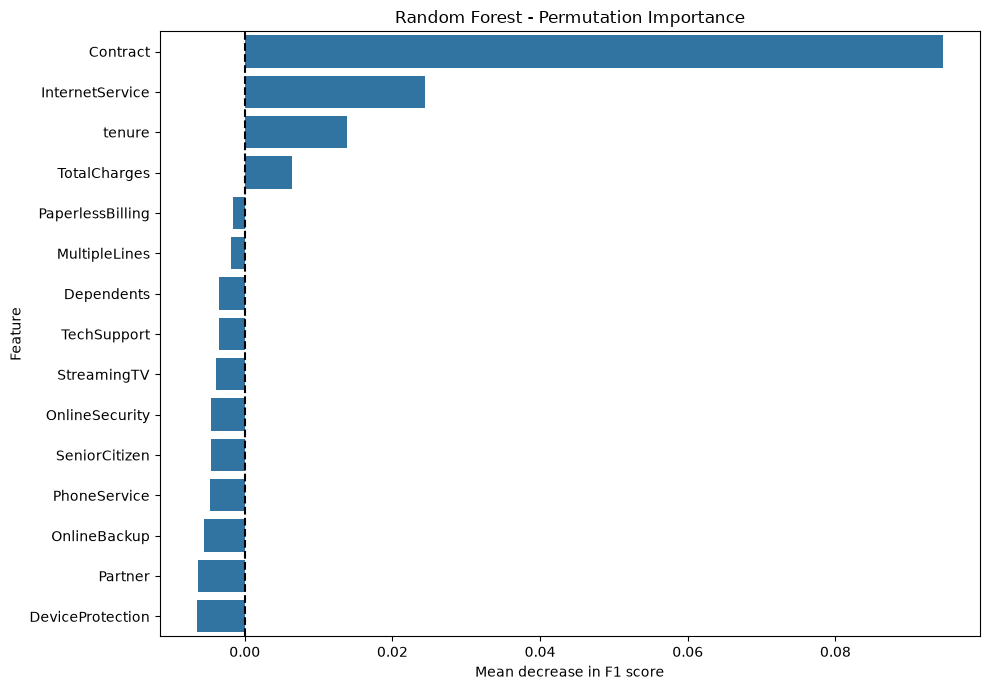

In [20]:
plt.figure(figsize=(10, 7))

sns.barplot(
    data=permutation_df.head(15),
    x="Importance",
    y="Feature"
)

plt.axvline(x=0, color="black", linestyle="--")

plt.title("Random Forest - Permutation Importance")
plt.xlabel("Mean decrease in F1 score")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

model_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Logistic Regression (Tuned)",
        "Random Forest",
        "Balanced Random Forest"
    ],
    "Accuracy": [0.8055, 0.7693, 0.7835, 0.7523],
    "Precision": [0.6572, 0.5516, 0.6186, 0.5247],
    "Recall": [0.5588, 0.7005, 0.4813, 0.7112],
    "F1 Score": [0.6040, 0.6172, 0.5414, 0.6039],
    "ROC-AUC": [0.8421, 0.8421, 0.8206, 0.8343]
})

model_results



,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.8055,0.6572,0.5588,0.6040,0.8421
1,Logistic Regression (Tuned),0.7693,0.5516,0.7005,0.6172,0.8421
2,Random Forest,0.7835,0.6186,0.4813,0.5414,0.8206
3,Balanced Random Forest,0.7523,0.5247,0.7112,0.6039,0.8343


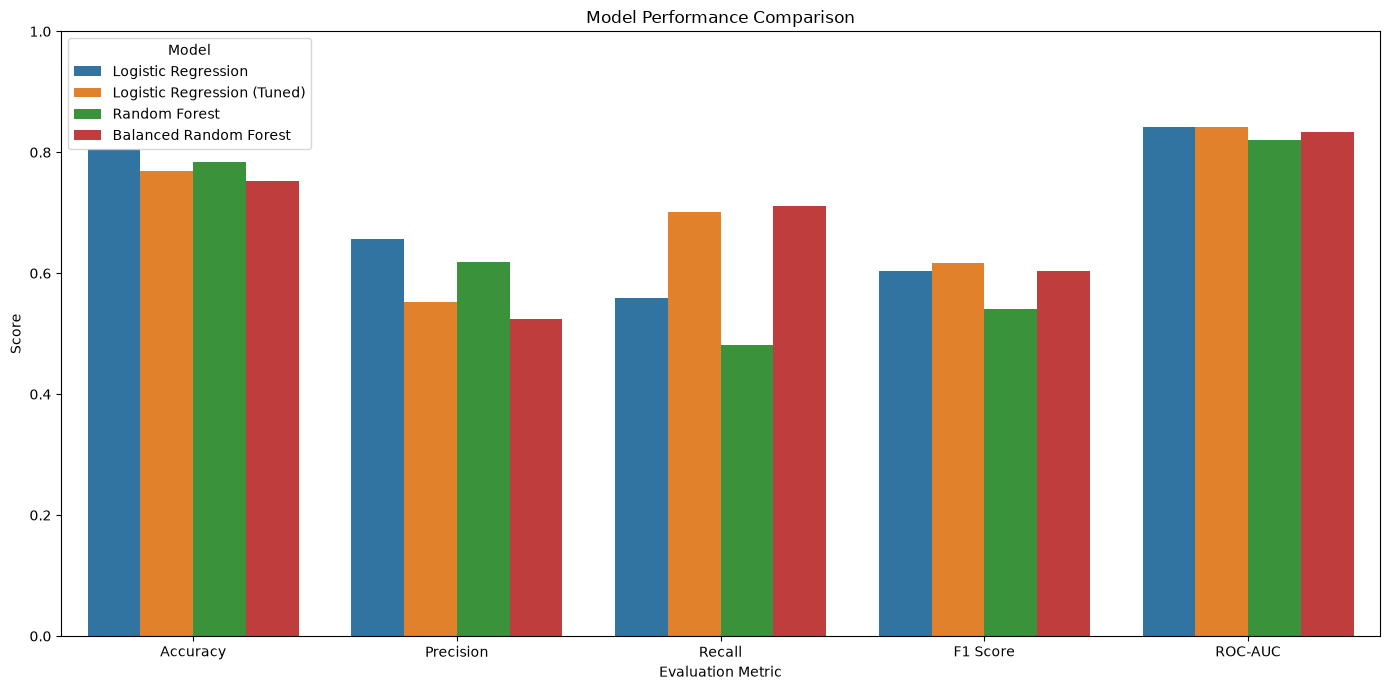

In [2]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC"
]

comparison = model_results.melt(
    id_vars="Model",
    value_vars=metrics,
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(14, 7))

sns.barplot(
    data=comparison,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.title("Model Performance Comparison")
plt.ylim(0, 1)
plt.ylabel("Score")
plt.xlabel("Evaluation Metric")
plt.legend(title="Model")
plt.tight_layout()
plt.show()

### Model Selection and Evaluation

Four model configurations were evaluated: Logistic Regression, Tuned Logistic Regression, Random Forest, and Balanced Random Forest.

Tuned Logistic Regression achieved the highest F1 score of 61.72%, with a recall of 70.05%. It provides a useful balance between identifying customers likely to churn and limiting false positive predictions.

Balanced Random Forest achieved the highest recall of 71.12%, making it a suitable alternative when identifying as many potential churners as possible is the primary objective.

Default Logistic Regression achieved the highest accuracy (80.55%), precision (65.72%), and ROC-AUC (84.21%).

Based on the evaluation, Tuned Logistic Regression was selected as the primary model because of its F1 score and relatively strong recall. The final choice depends on the business cost of missed churners versus unnecessary retention interventions.


In [8]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Load cleaned dataset
df = pd.read_csv("../data/processed/cleaned_customer_data.csv")

# Remove customer identifier
df = df.drop(columns=["customerID"])

# Separate features and target
X = df.drop(columns=["Churn"])
y = df["Churn"].map({"No": 0, "Yes": 1})

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Identify numerical and categorical features
numerical_features = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

categorical_features = [
    col for col in X_train.columns
    if col not in numerical_features
]

# Create preprocessing pipeline
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numerical_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("Preprocessor created successfully.")

Training data: (5634, 19)
Testing data: (1409, 19)
Preprocessor created successfully.


In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numerical_features = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

categorical_features = [
    col for col in X_train.columns
    if col not in numerical_features
]

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numerical_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])

In [10]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
import pandas as pd
import numpy as np

# Create Logistic Regression pipeline
cv_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Create 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate multiple metrics
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

cv_results = cross_validate(
    cv_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

# Display results
cv_df = pd.DataFrame({
    "Accuracy": cv_results["test_accuracy"],
    "Precision": cv_results["test_precision"],
    "Recall": cv_results["test_recall"],
    "F1 Score": cv_results["test_f1"],
    "ROC-AUC": cv_results["test_roc_auc"]
})

print("Individual fold results:")
display(cv_df)

print("\nAverage cross-validation scores:")
print(cv_df.mean())

print("\nStandard deviation:")
print(cv_df.std())

Individual fold results:


,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,0.799468,0.647773,0.535117,0.586081,0.847919
1,0.781721,0.607287,0.501672,0.549451,0.825180
2,0.802130,0.658333,0.528428,0.586271,0.841917
3,0.816327,0.664286,0.622074,0.642487,0.862967
4,0.810835,0.686957,0.528428,0.597353,0.853021



Average cross-validation scores:
Accuracy     0.802096
Precision    0.652927
Recall       0.543144
F1 Score     0.592329
ROC-AUC      0.846201
dtype: float64

Standard deviation:
Accuracy     0.013237
Precision    0.029265
Recall       0.045955
F1 Score     0.033374
ROC-AUC      0.014061
dtype: float64


In [11]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

cv_probabilities = cross_val_predict(
    cv_model,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

tuned_threshold = 0.3645330665

cv_predictions = (
    cv_probabilities >= tuned_threshold
).astype(int)

print("Tuned threshold:", tuned_threshold)
print("Accuracy:", accuracy_score(y_train, cv_predictions))
print("Precision:", precision_score(y_train, cv_predictions))
print("Recall:", recall_score(y_train, cv_predictions))
print("F1 Score:", f1_score(y_train, cv_predictions))

Tuned threshold: 0.3645330665
Accuracy: 0.7839900603478879
Precision: 0.5767955801104973
Recall: 0.6983277591973244
F1 Score: 0.6317700453857791


### Cross-Validation and Threshold Optimization

Five-fold stratified cross-validation was performed to evaluate Logistic Regression.

At the default classification threshold of 0.5, the model achieved an average accuracy of 80.21%, precision of 65.29%, recall of 54.31%, F1 score of 59.23%, and ROC-AUC of 84.62%.

The classification threshold was then reduced to 0.3645 to improve churn detection. Using out-of-fold predictions, the tuned threshold achieved:

- Accuracy: 78.40%
- Precision: 57.68%
- Recall: 69.83%
- F1 Score: 63.18%

The tuned threshold improved recall and F1 score while reducing accuracy and precision. This demonstrates the trade-off between identifying more potential churners and generating additional false positive predictions.

Tuned Logistic Regression was retained as the primary model for further evaluation.


In [12]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Create final Logistic Regression pipeline
final_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Train on the complete training set
final_model.fit(X_train, y_train)

print("Final model trained successfully.")

Final model trained successfully.


In [13]:
# Get churn probabilities
y_test_prob = final_model.predict_proba(X_test)[:, 1]

# Apply tuned threshold
final_threshold = 0.3645330665

y_test_pred = (
    y_test_prob >= final_threshold
).astype(int)

In [14]:
final_metrics = {
    "Accuracy": accuracy_score(y_test, y_test_pred),
    "Precision": precision_score(y_test, y_test_pred),
    "Recall": recall_score(y_test, y_test_pred),
    "F1 Score": f1_score(y_test, y_test_pred),
    "ROC-AUC": roc_auc_score(y_test, y_test_prob)
}

for metric, score in final_metrics.items():
    print(f"{metric}: {score:.4f} ({score*100:.2f}%)")

Accuracy: 0.7693 (76.93%)
Precision: 0.5516 (55.16%)
Recall: 0.7005 (70.05%)
F1 Score: 0.6172 (61.72%)
ROC-AUC: 0.8421 (84.21%)


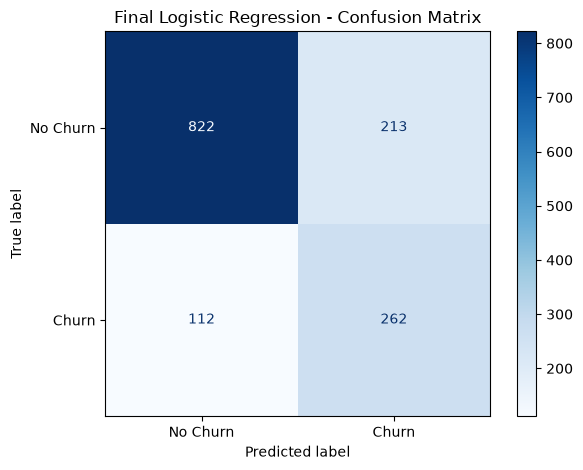

              precision    recall  f1-score   support

    No Churn       0.88      0.79      0.83      1035
       Churn       0.55      0.70      0.62       374

    accuracy                           0.77      1409
   macro avg       0.72      0.75      0.73      1409
weighted avg       0.79      0.77      0.78      1409



In [15]:
cm = confusion_matrix(y_test, y_test_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
)

display.plot(cmap="Blues")
plt.title("Final Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()

print(classification_report(
    y_test,
    y_test_pred,
    target_names=["No Churn", "Churn"]
))

### Final Model Evaluation

The final Tuned Logistic Regression model was trained using the complete training dataset and evaluated on the test dataset using a classification threshold of 0.3645.

The model achieved:

- Accuracy: 76.93%
- Precision: 55.16%
- Recall: 70.05%
- F1 Score: 61.72%
- ROC-AUC: 84.21%

The confusion matrix showed 262 true positives, 822 true negatives, 213 false positives and 112 false negatives.

The model successfully identified approximately 70% of actual churners. Although lowering the classification threshold increased recall, it also increased false positive predictions.

The results demonstrate that Logistic Regression can provide useful customer churn predictions and support targeted customer-retention strategies. However, further improvements in precision and recall would be beneficial before real-world deployment.